# ENADE 2023 — Engenharia de Computação: UNIFOR e privadas presenciais

Recorte corrigido: grupo 6411, categorias 4/5/8, presencial; 70 IES e 79 cursos.
A execução valida a fase 1 antes de gerar resultados. Fontes: ZIPs oficiais INEP locais.
Não se associam estudantes entre arquivos. O módulo agrega notas por curso antes de
relacionar atributos institucionais; o arq1 serve apenas para cadastro e contagem.

**Denominadores:** participação = TP_PRES em 555/888 dividido por inscritos;
ausência = 222/444 dividido por inscritos. O eliminado 334 fica separado.
Resultado oficial válido (555) inclui os suprimidos; estatísticas usam somente
IN_NOTA_VALIDA=1 (três notas publicadas e participação considerada).

Desvio-padrão amostral usa ddof=1. Média dos participantes pondera os cursos pelo
número de notas; média entre cursos dá peso igual a cada curso com nota. Cursos
sem nota não entram em médias. n ≥ 10 só limita comparações destacadas, preservando
todos os cursos nas tabelas. Grupos sem fins lucrativos (Censo IES=5) e universidades
privadas (ENADE CO_ORGACAD=10028) incluem a UNIFOR e se sobrepõem; a tabela também
mostra privadas sem UNIFOR como conferência descritiva.

Notas brutas 0–100 não são o Conceito Enade (indicador de curso em escala 1–5).
Não há teste de superioridade, inferência causal ou ranking definitivo. Sigilo,
seleção dos participantes e perfis de cursos limitam as comparações. Ciência da
Computação 2021 permanece etapa futura.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src/preparar_2023.py').exists()
assert Path(sys.executable).resolve() == (ROOT / '.venv/Scripts/python.exe').resolve(), sys.executable
sys.path.insert(0, str(ROOT / 'src'))
from analisar_2023 import analyze
resultado = analyze(ROOT)
print('Python:', sys.executable)

FASE 1 APROVADA: filtros, chaves, notas, sigilo, UNIFOR, CSVs e ZIPs.


FASE 2: 273 verificações estatísticas; 4 gráficos e 3 tabelas validados.
Python: C:\trabCDados\projeto-enade\.venv\Scripts\python.exe


## Amostras e participação
Taxas em percentual dos inscritos de cada grupo. Suprimidos contam como presentes, sem nota utilizável.

In [2]:
display(resultado['participacao'].round(3))

,grupo,instituicoes,cursos,cursos_com_notas,cursos_n10,inscritos,presentes,presencas_validas_oficiais,ausentes,suprimidos,outros,n_validas,taxa_participacao_pct,taxa_ausencia_pct,taxa_notas_publicadas_pct
0,UNIFOR,1,1,1,1,30,25,25,5,0,0,25,83.333,16.667,83.333
1,privado_presencial,70,79,71,47,1418,1209,1209,208,6,1,1203,85.261,14.669,84.838
2,sem_fins_lucrativos,36,39,34,24,755,680,680,74,4,1,676,90.066,9.801,89.536
3,universidades_privadas,20,29,28,21,601,522,522,79,1,0,521,86.855,13.145,86.689
4,privado_sem_unifor,69,78,70,46,1388,1184,1184,203,6,1,1178,85.303,14.625,84.870


## Estatísticas e ponderação
Média, mediana e desvio-padrão são calculados por participantes com notas publicadas válidas. As duas últimas colunas mostram médias de cursos com pesos iguais.

In [3]:
display(resultado['estatisticas'].round(3))

,grupo,nota,n_notas,n_cursos_com_notas,media_participantes,mediana_participantes,desvio_padrao_amostral,media_nao_ponderada_cursos,media_nao_ponderada_cursos_n10
0,UNIFOR,NT_GER,25,1,41.656,41.20,9.301,41.656,41.656
1,UNIFOR,NT_FG,25,1,47.776,50.60,12.374,47.776,47.776
2,UNIFOR,NT_CE,25,1,39.600,38.00,10.721,39.600,39.600
3,privado_presencial,NT_GER,1203,71,39.326,38.60,11.985,38.005,39.535
4,privado_presencial,NT_FG,1203,71,51.550,51.20,15.946,49.877,51.596
5,privado_presencial,NT_CE,1203,71,35.234,33.80,13.496,34.030,35.497
6,sem_fins_lucrativos,NT_GER,676,34,42.440,41.80,11.749,40.761,42.366
7,sem_fins_lucrativos,NT_FG,676,34,52.737,52.80,15.931,50.444,52.363
8,sem_fins_lucrativos,NT_CE,676,34,38.989,37.80,13.233,37.515,39.015
9,universidades_privadas,NT_GER,521,28,38.164,37.50,11.820,38.913,39.739


## Cursos, incluindo amostras pequenas
A tabela completa é salva em resultados/tabelas/estatisticas_cursos_2023.csv. Nenhum curso é apagado por n pequeno.

In [4]:
display(resultado['cursos'][['CO_CURSO','NO_IES','inscritos','n_validas','DESTAQUE_N10','NT_GER_mean']])

,CO_CURSO,NO_IES,inscritos,n_validas,DESTAQUE_N10,NT_GER_mean
0,872,PONTIFÍCIA UNIVERSIDADE CATÓLICA DO PARANÁ,22,20,1,44.555000
1,5500,UNIVERSIDADE SÃO JUDAS TADEU,62,51,1,31.343137
2,8170,UNIVERSIDADE CATÓLICA DOM BOSCO,20,19,1,35.226316
3,15490,UNIVERSIDADE SÃO FRANCISCO,23,22,1,36.295455
4,18185,CENTRO UNIVERSITÁRIO DE LINS,5,5,0,39.200000
...,...,...,...,...,...,...
74,1473932,UNIVERSIDADE SÃO JUDAS TADEU,6,6,0,36.483333
75,1474136,UNIVERSIDADE SÃO JUDAS TADEU,13,11,1,34.309091
76,5000186,FACULDADE ESAMC SANTOS,20,17,1,35.352941
77,5000188,CENTRO UNIVERSITÁRIO ESPÍRITO-SANTENSE/FAESA,19,19,1,41.910526


## Distribuição, dispersão, médias e participação
As figuras registram fontes e amostras. A dispersão destaca apenas n ≥ 10; histogramas e médias gerais usam todas as notas publicadas válidas.

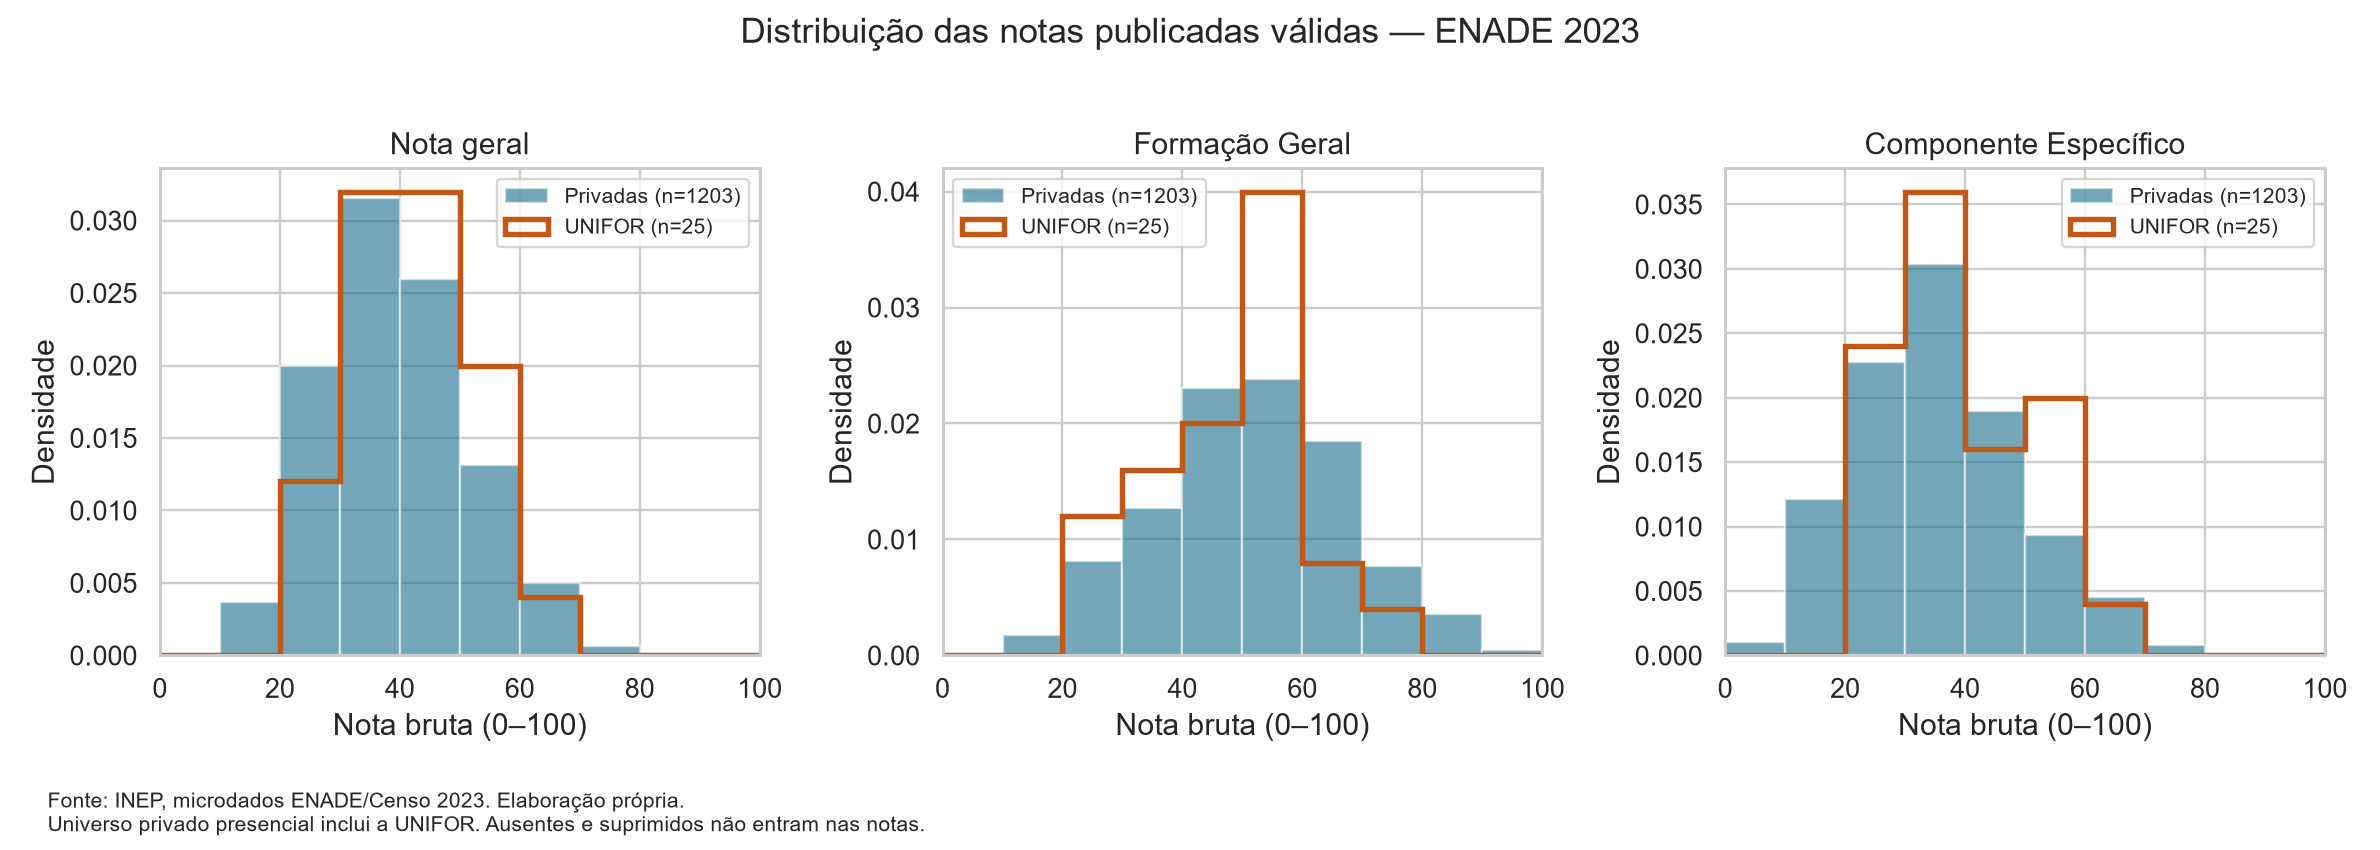

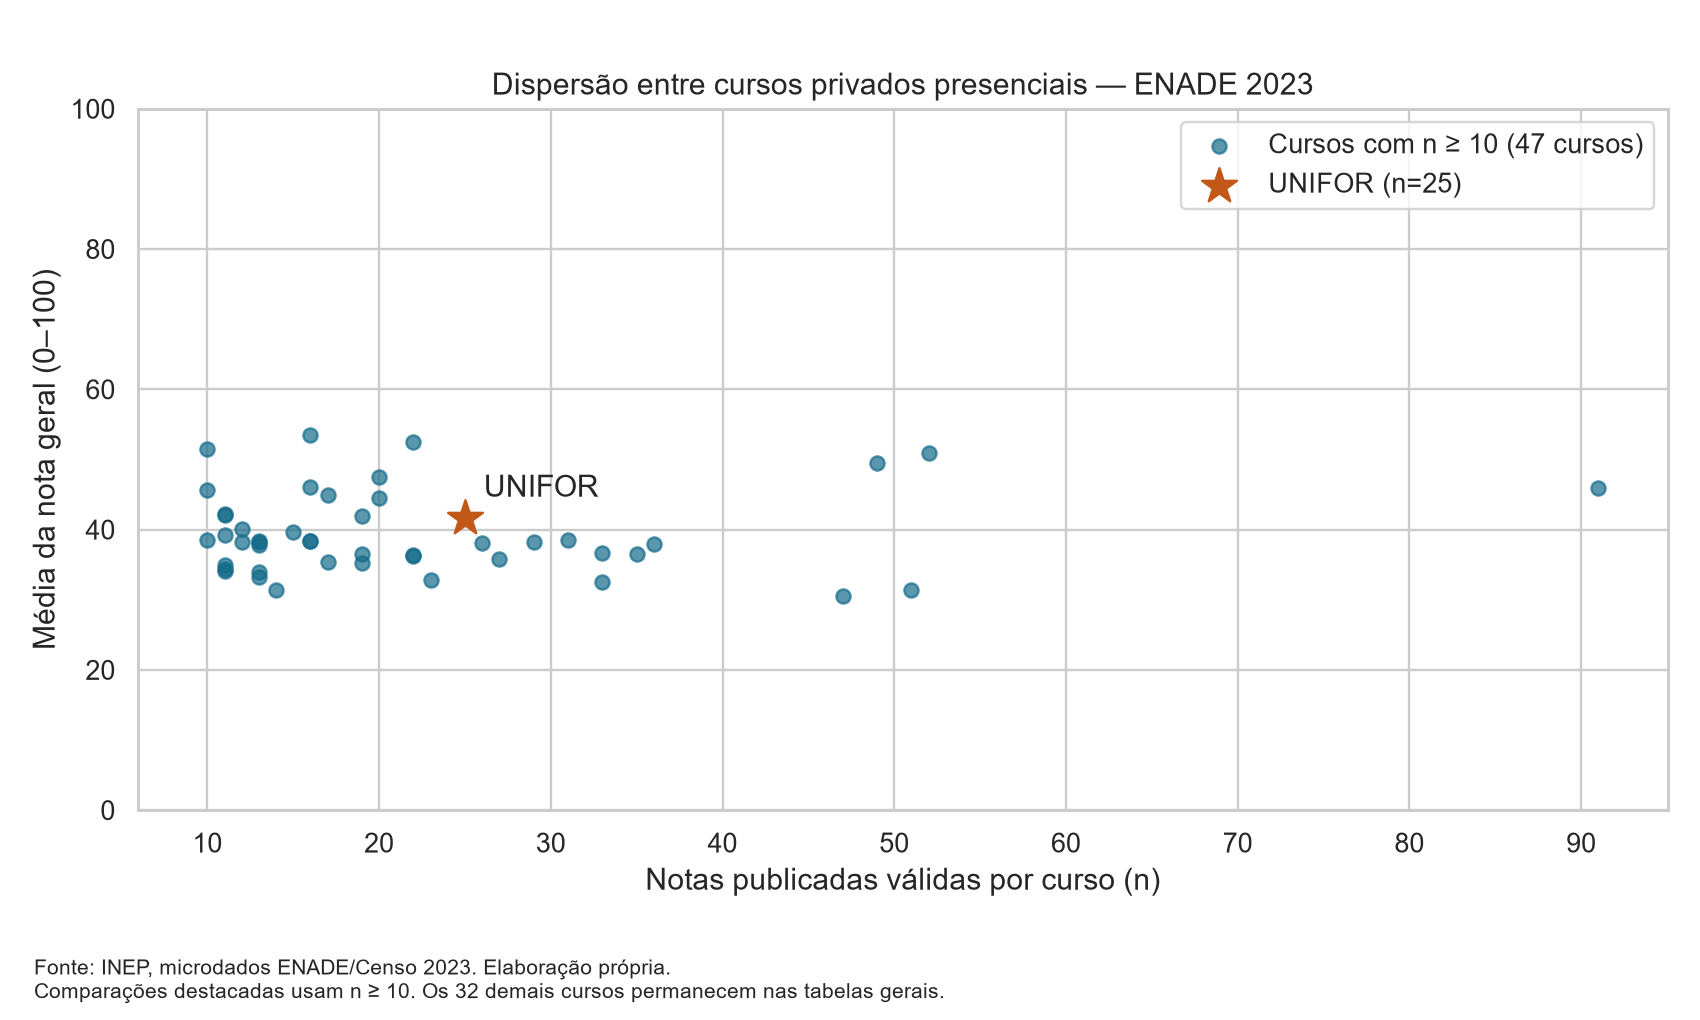

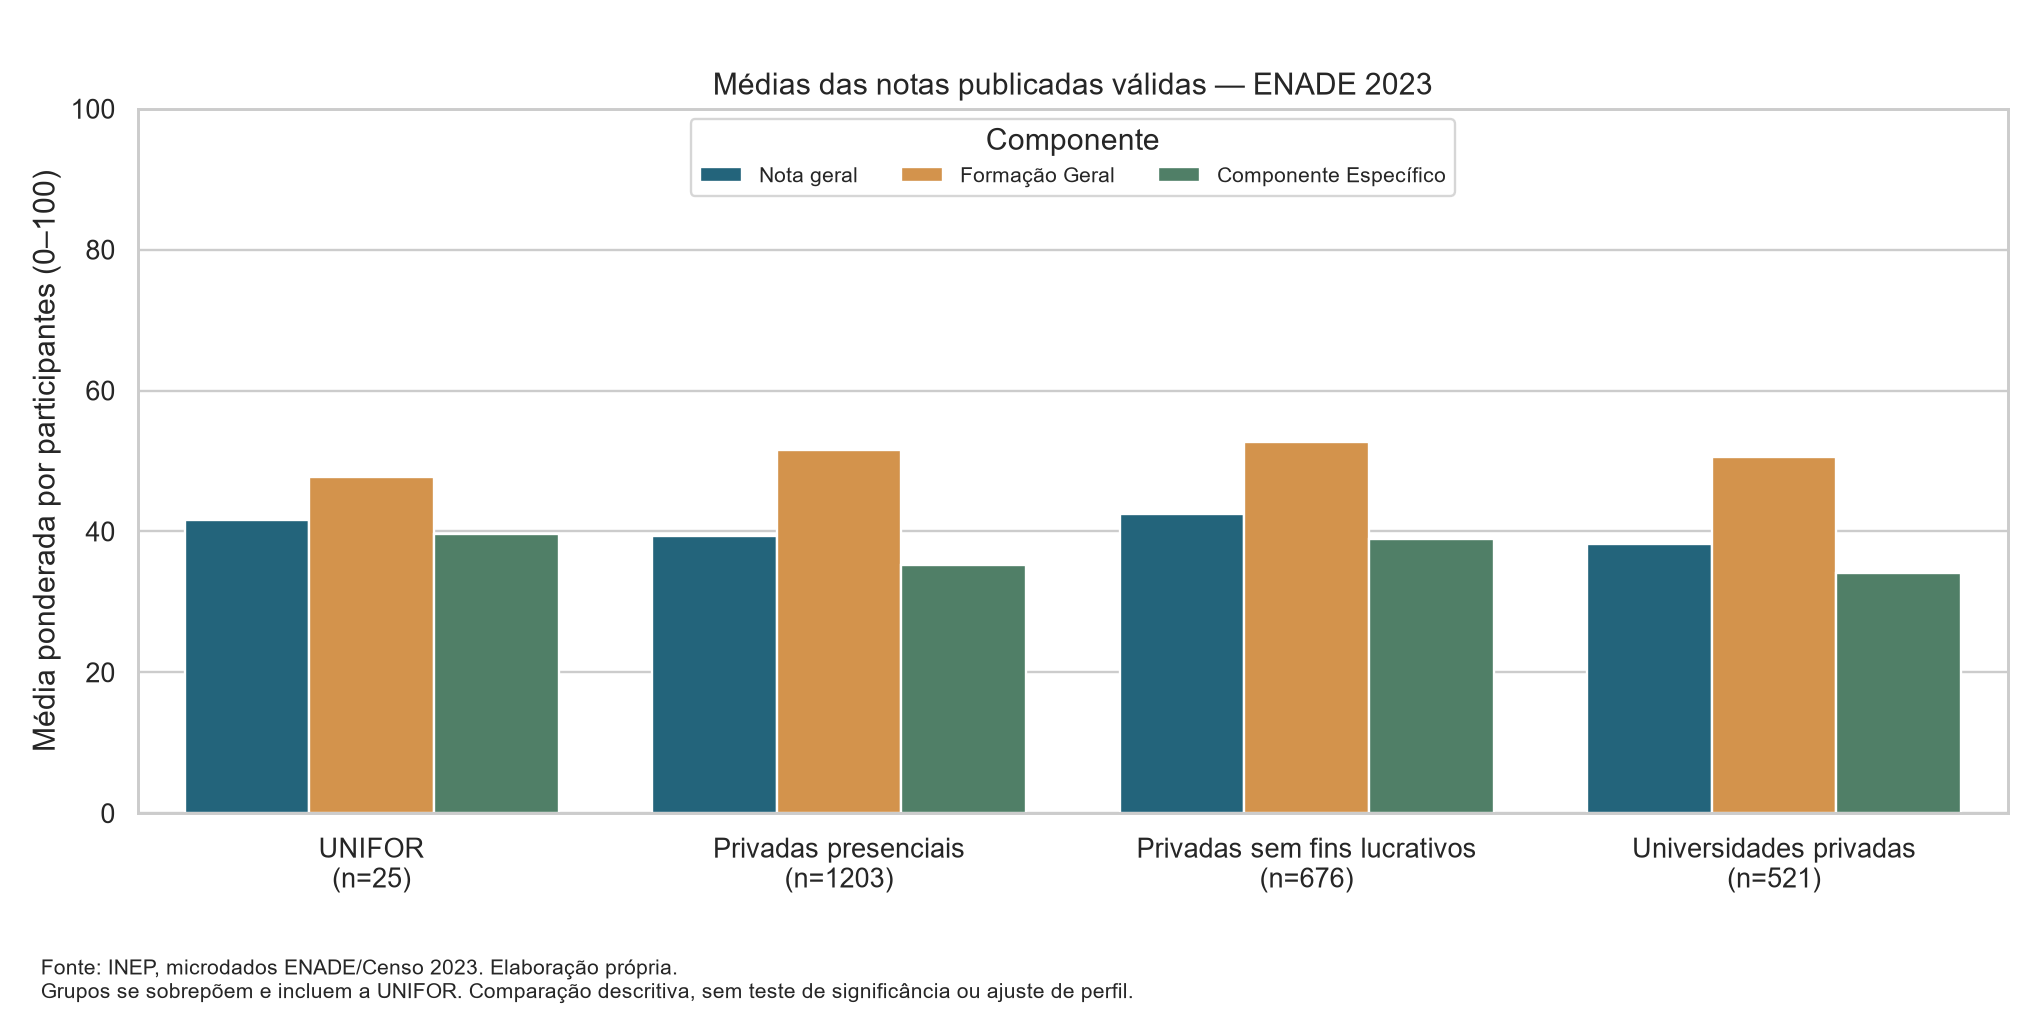

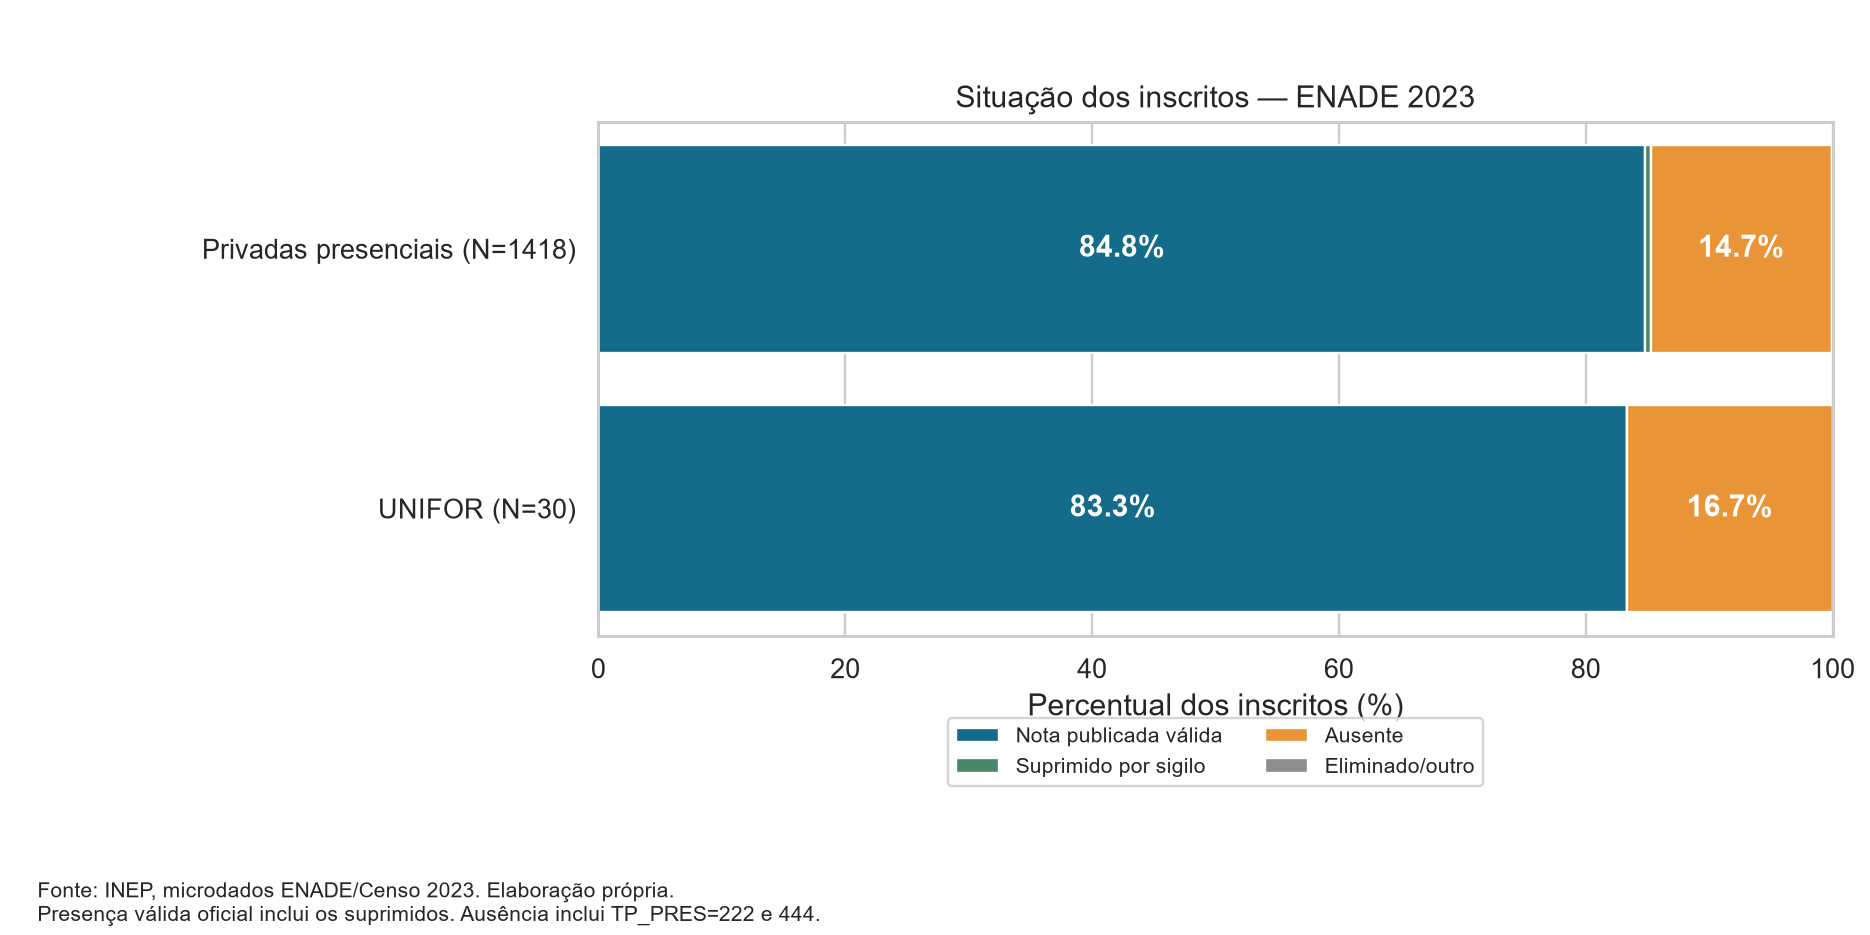

In [5]:
from IPython.display import Image, display
for nome in resultado['validacao']['graficos']:
    display(Image(filename=str(ROOT / 'resultados/graficos' / nome)))

## Verificação e reprodução

Cada média, mediana e desvio-padrão dos grupos é conferido pela biblioteca
`statistics` e as médias são reconciliadas com somas/contagens por curso.
As médias de cada curso também são verificadas independentemente.
Tabelas são relidas e comparadas; hashes vinculam entradas e saídas.
Veja docs/analise_2023.md e resultados/tabelas/validacao_analise_2023.json.
Execute todas as células com o kernel **Python (projeto-enade)**.
As conclusões descritivas validadas constam no relatório; não se faz imputação,
reidentificação nem comparação com dados de 2021.